In [1]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

In [5]:
pd.set_option('display.max_rows', None)
df = sns.load_dataset("taxis")
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.00,2.15,0.00,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.00,0.00,0.00,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.50,2.36,0.00,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.00,6.15,0.00,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.00,1.10,0.00,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
5,2019-03-11 10:37:23,2019-03-11 10:47:31,1,0.49,7.50,2.16,0.00,12.96,yellow,credit card,Times Sq/Theatre District,Midtown East,Manhattan,Manhattan
6,2019-03-26 21:07:31,2019-03-26 21:17:29,1,3.65,13.00,2.00,0.00,18.80,yellow,credit card,Battery Park City,Two Bridges/Seward Park,Manhattan,Manhattan
7,2019-03-22 12:47:13,2019-03-22 12:58:17,0,1.40,8.50,0.00,0.00,11.80,yellow,NaN,Murray Hill,Flatiron,Manhattan,Manhattan
8,2019-03-23 11:48:50,2019-03-23 12:06:14,1,3.63,15.00,1.00,0.00,19.30,yellow,credit card,East Harlem South,Midtown Center,Manhattan,Manhattan
9,2019-03-08 16:18:37,2019-03-08 16:26:57,1,1.52,8.00,1.00,0.00,13.30,yellow,credit card,Lincoln Square East,Central Park,Manhattan,Manhattan


In [6]:
df.shape

(6433, 14)

In [7]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [8]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [9]:
df[["payment","pickup_zone","dropoff_zone","pickup_borough","dropoff_borough"]]

,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
5,credit card,Times Sq/Theatre District,Midtown East,Manhattan,Manhattan
6,credit card,Battery Park City,Two Bridges/Seward Park,Manhattan,Manhattan
7,NaN,Murray Hill,Flatiron,Manhattan,Manhattan
8,credit card,East Harlem South,Midtown Center,Manhattan,Manhattan
9,credit card,Lincoln Square East,Central Park,Manhattan,Manhattan


In [10]:
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])

In [11]:
df["pickup_zone"]=df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])

In [12]:
df["dropoff_zone"]=df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])


In [13]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment             0
pickup_zone         0
dropoff_zone        0
pickup_borough     26
dropoff_borough    45
dtype: int64

In [14]:
df = df[df["pickup_borough"].notnull()]
df = df[df["dropoff_borough"].notnull()]

In [15]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [16]:
df["pickup"] = pd.to_datetime(df["pickup"])

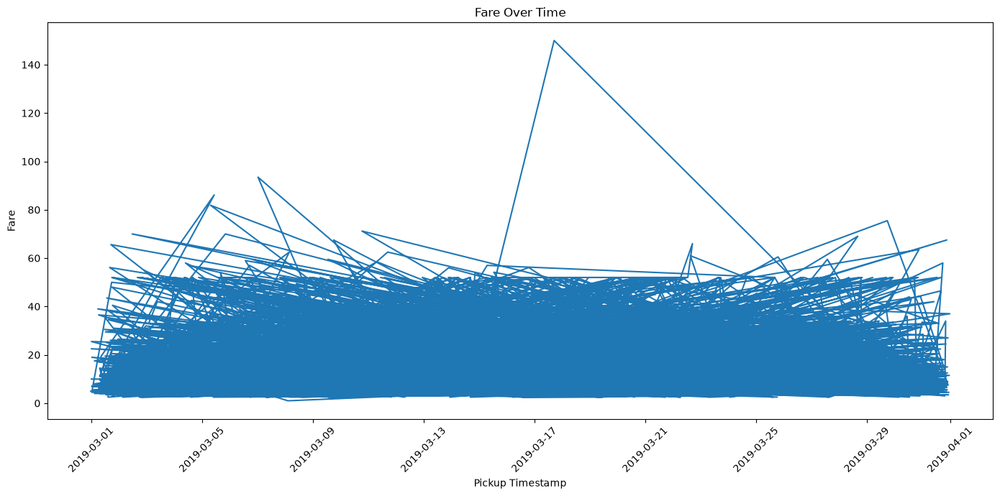

In [17]:
plt.figure(figsize=(14, 7))
plt.plot(df["pickup"], df["fare"])
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.title("Fare Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
bfare = df.groupby("pickup_borough")["fare"].sum()
bfare

pickup_borough
Bronx         2078.91
Brooklyn      6227.48
Manhattan    58323.92
Queens       15541.06
Name: fare, dtype: float64

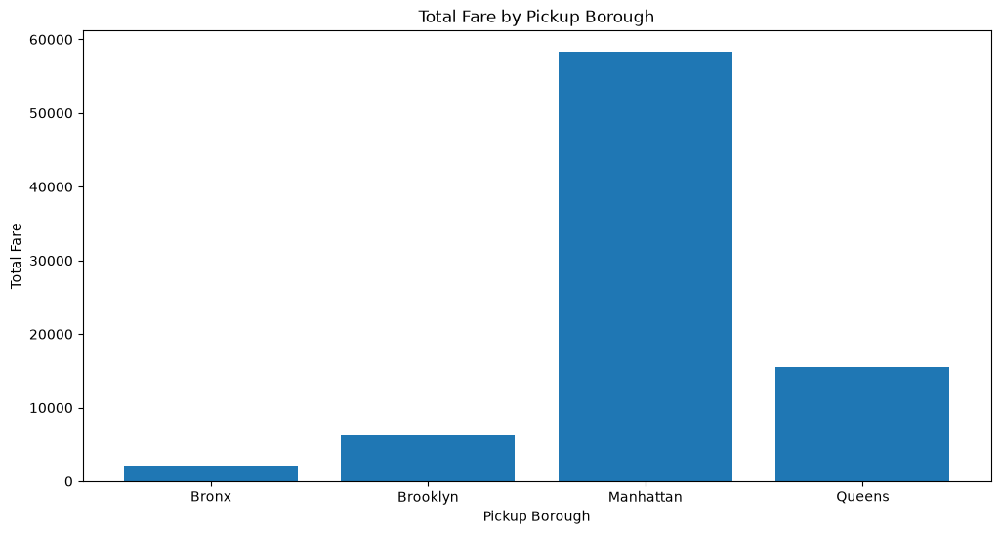

In [19]:
plt.figure(figsize=(12, 6))

plt.bar(bfare.index, bfare.values)

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")

plt.show()

In [20]:
paymentcount = df["payment"].value_counts()
paymentcount

payment
credit card    4588
cash           1795
Name: count, dtype: int64

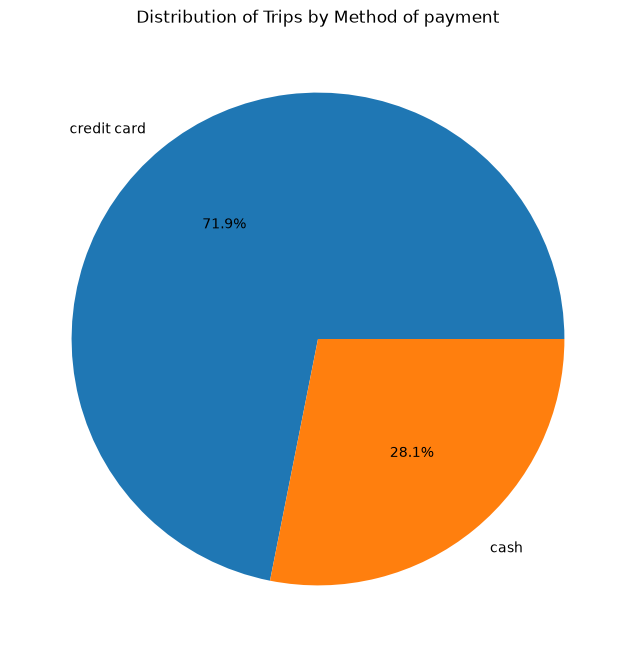

In [21]:
plt.figure(figsize=(16, 8))

plt.pie(paymentcount.values, labels=paymentcount.index, autopct="%1.1f%%")

plt.title("Distribution of Trips by Method of payment")
plt.show()

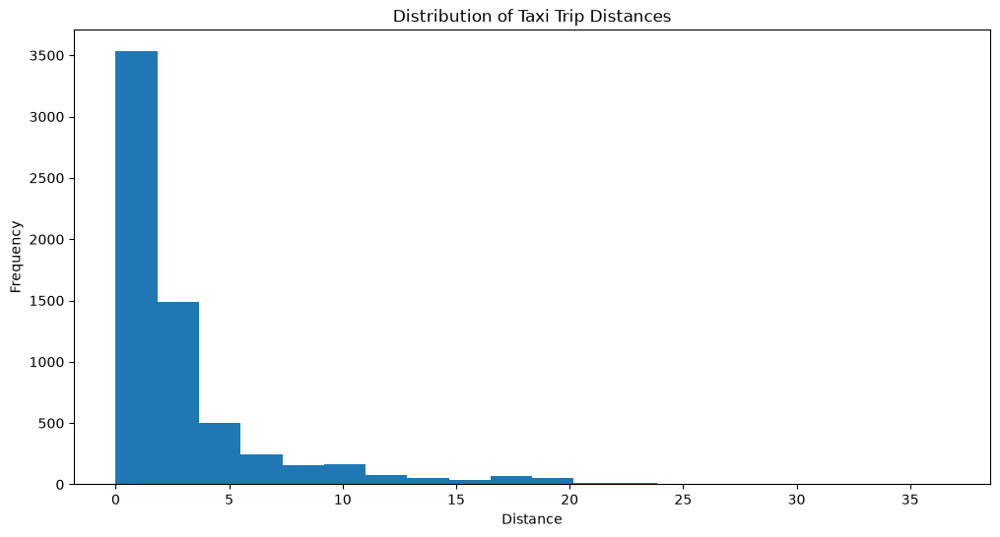

In [22]:
plt.figure(figsize=(12, 6))
plt.hist(df["distance"], bins=20)
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Taxi Trip Distances")

plt.show()


In [23]:
boroughs = df["pickup_borough"].unique()

tipdata = [df[df["pickup_borough"] == borough]["tip"] for borough in boroughs]

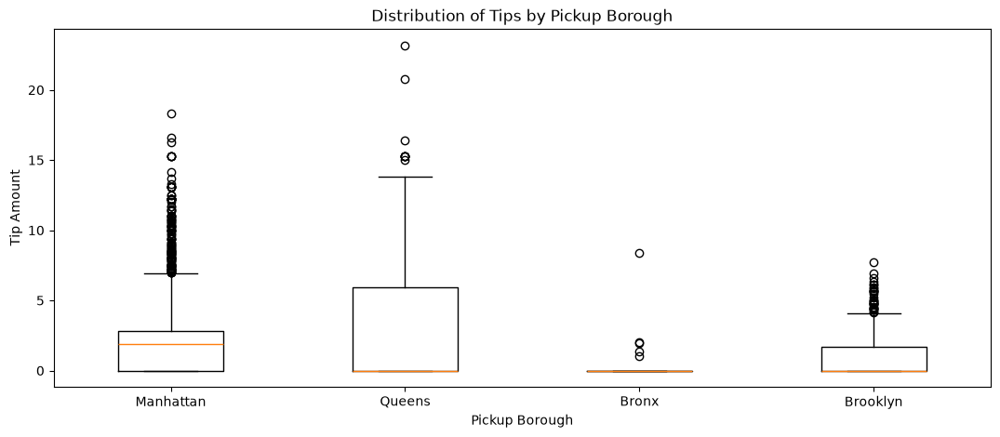

In [24]:
plt.figure(figsize=(13, 5))

plt.boxplot(tipdata, tick_labels=boroughs)

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Distribution of Tips by Pickup Borough")

plt.show()

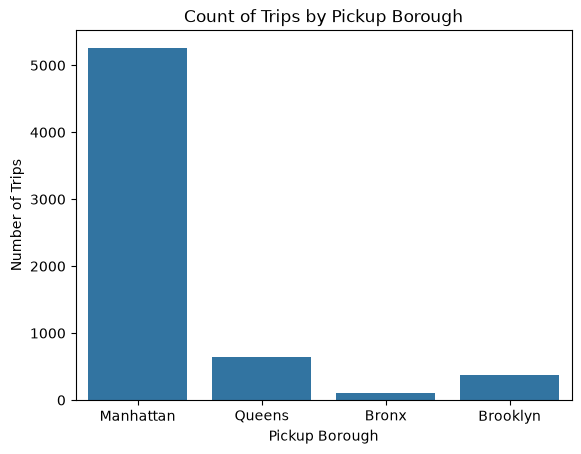

In [25]:
sns.countplot(data=df, x="pickup_borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Count of Trips by Pickup Borough")
plt.show()


<Axes: xlabel='distance', ylabel='fare'>

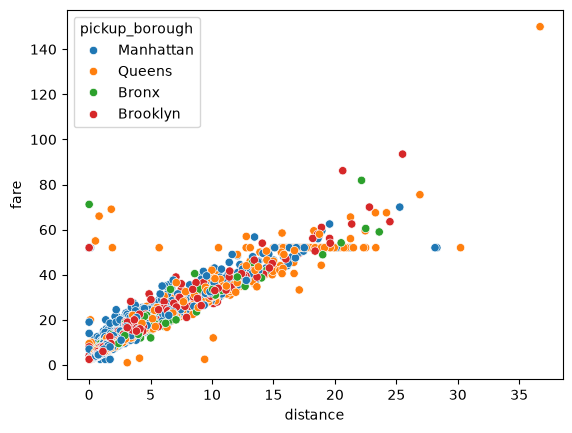

In [26]:
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough")

In [27]:
numdf=df.select_dtypes(include="number")
numdf.corr()

,passengers,distance,fare,tip,tolls,total
passengers,1.000000,0.005467,-0.000445,0.020019,-0.003392,0.009174
distance,0.005467,1.000000,0.947021,0.475378,0.642899,0.928371
fare,-0.000445,0.947021,1.000000,0.485655,0.618184,0.972376
tip,0.020019,0.475378,0.485655,1.000000,0.412787,0.649050
tolls,-0.003392,0.642899,0.618184,0.412787,1.000000,0.691506
total,0.009174,0.928371,0.972376,0.649050,0.691506,1.000000


<Axes: >

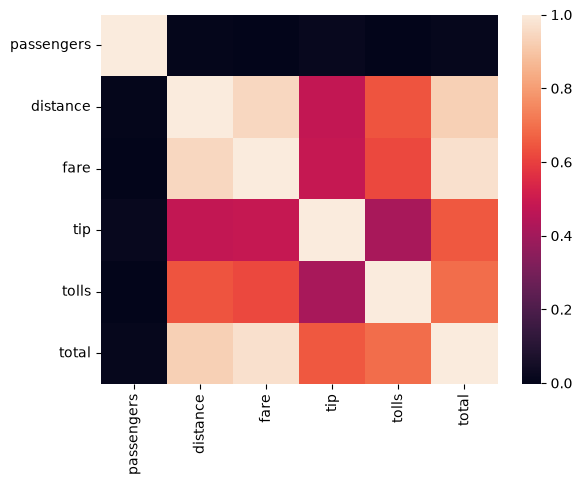

In [28]:
sns.heatmap(numdf.corr())

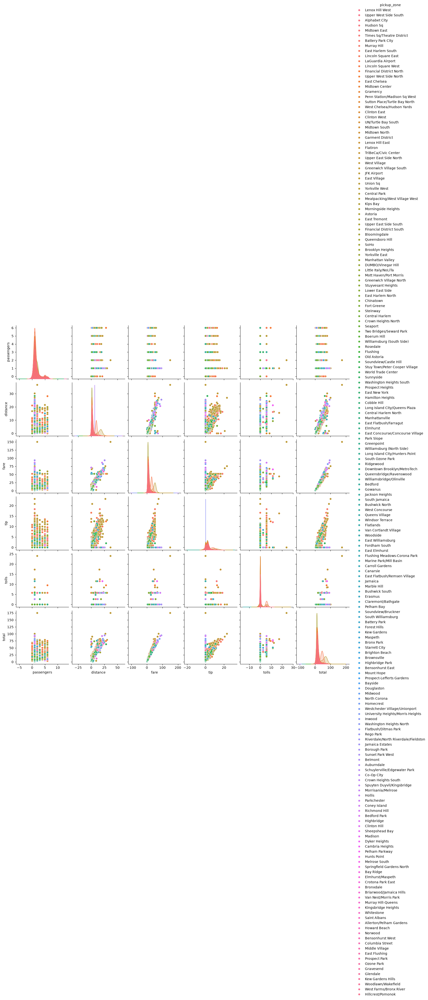

In [30]:
sns.pairplot(df,hue="pickup_zone")
plt.show()

Text(0.5, 1.0, 'Fare Distribution by Payment Method')

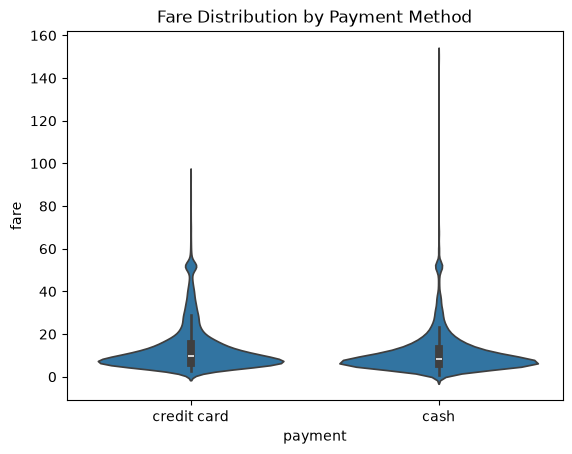

In [31]:
sns.violinplot(data=df,x="payment",y="fare")

plt.title("Fare Distribution by Payment Method")